In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_style("whitegrid")

In [11]:
# Load the original dataset
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("Dataset loaded successfully.")
df.head()

Dataset loaded successfully.


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [12]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 7043
Number of columns: 21


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [14]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [15]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [16]:
# Missing values in the raw dataset
df.isnull().sum().sort_values(ascending=False)

customerID          0
DeviceProtection    0
TotalCharges        0
MonthlyCharges      0
PaymentMethod       0
PaperlessBilling    0
Contract            0
StreamingMovies     0
StreamingTV         0
TechSupport         0
OnlineBackup        0
gender              0
OnlineSecurity      0
InternetService     0
MultipleLines       0
PhoneService        0
tenure              0
Dependents          0
Partner             0
SeniorCitizen       0
Churn               0
dtype: int64

In [17]:
# Inspect blank TotalCharges values
blank_total_charges = df["TotalCharges"].astype(str).str.strip().eq("").sum()
print("Blank TotalCharges values:", blank_total_charges)

Blank TotalCharges values: 11


In [18]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].astype(str).str.strip(),
    errors="coerce"
)

print("Missing TotalCharges after conversion:", df["TotalCharges"].isna().sum())

Missing TotalCharges after conversion: 11


In [19]:
# Inspect the affected records
df.loc[df["TotalCharges"].isna(),
       ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [20]:
# Fill missing TotalCharges for zero-tenure customers
df["TotalCharges"] = df["TotalCharges"].fillna(0)

print("Missing TotalCharges after cleaning:", df["TotalCharges"].isna().sum())

Missing TotalCharges after cleaning: 0


In [21]:
print("Duplicate rows:", df.duplicated().sum())


Duplicate rows: 0


In [22]:
df.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object

Derived features are created to support analysis:
- `ChurnFlag`: converts churn into 0/1.
- `SeniorCitizenLabel`: converts the numeric senior-citizen indicator into readable labels.
- `TenureGroup`: groups customers into meaningful tenure bands.


In [23]:
df["ChurnFlag"] = df["Churn"].map({"No": 0, "Yes": 1})

df["SeniorCitizenLabel"] = df["SeniorCitizen"].map({
    0: "No",
    1: "Yes"
})

df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12 months", "13-24 months", "25-48 months", "49-72 months"]
)

df.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,ChurnFlag,SeniorCitizenLabel,TenureGroup
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0,No,0-12 months
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No,0,No,25-48 months
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,No,0-12 months
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,0,No,25-48 months
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,No,0-12 months


In [24]:
churn_counts = df["Churn"].value_counts()
print(churn_counts)

churn_rate = df["ChurnFlag"].mean() * 100
print(f"Overall churn rate: {churn_rate:.2f}%")

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Overall churn rate: 26.54%


### Visualization 1 — Customer Churn Distribution

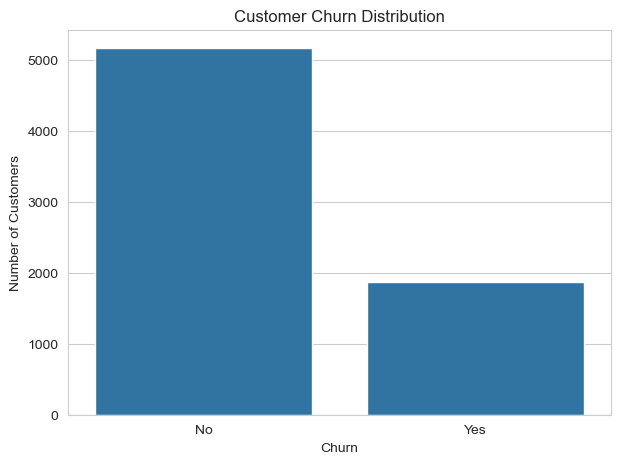

In [25]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

### Visualization 2 — Churn by Gender

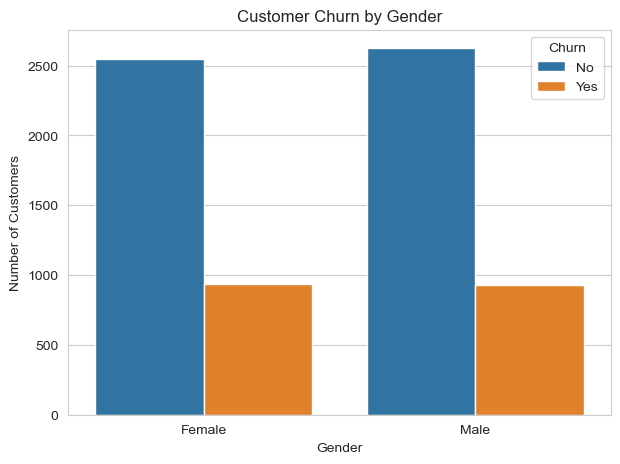

In [26]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="gender", hue="Churn")
plt.title("Customer Churn by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")
plt.show()

### Visualization 3 — Churn by Contract Type

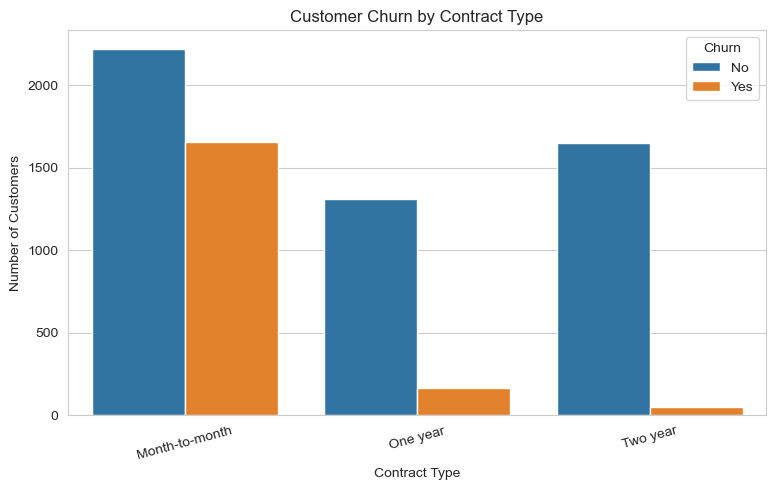

In [27]:
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="Contract", hue="Churn")
plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)
plt.show()

In [28]:
contract_churn = pd.crosstab(
    df["Contract"], df["Churn"], normalize="index"
) * 100

print("Churn percentage by contract type:")
contract_churn.round(2)

Churn percentage by contract type:


Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


### Visualization 4 — Churn by Internet Service

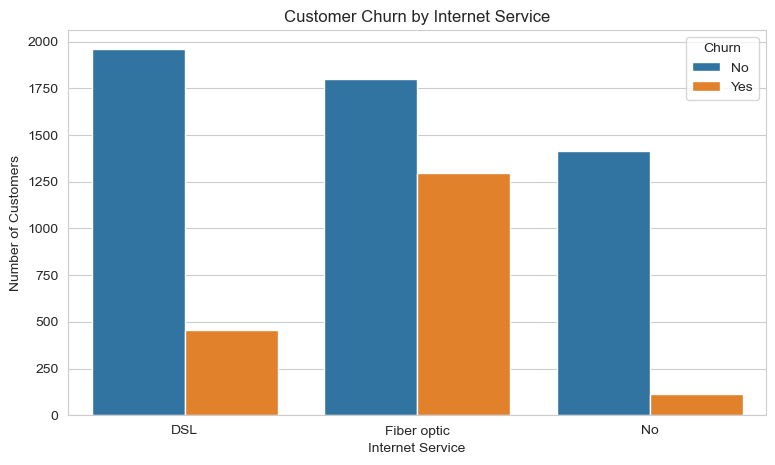

In [29]:
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="InternetService", hue="Churn")
plt.title("Customer Churn by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")
plt.show()

In [30]:
internet_churn = pd.crosstab(
    df["InternetService"], df["Churn"], normalize="index"
) * 100

print("Churn percentage by internet service:")
internet_churn.round(2)

Churn percentage by internet service:


Churn,No,Yes
InternetService,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


### Visualization 5 — Churn by Payment Method

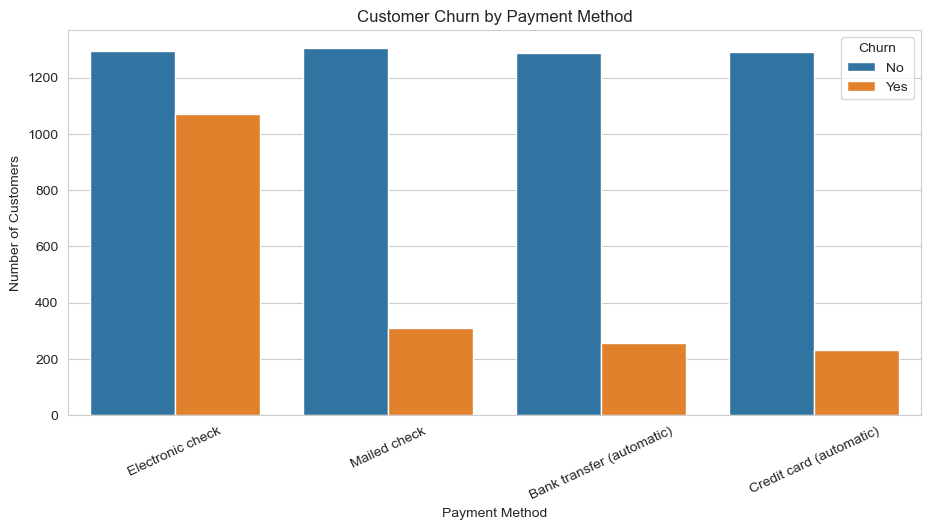

In [31]:
plt.figure(figsize=(11, 5))
sns.countplot(data=df, x="PaymentMethod", hue="Churn")
plt.title("Customer Churn by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")
plt.xticks(rotation=25)
plt.show()

In [32]:
payment_churn = pd.crosstab(
    df["PaymentMethod"], df["Churn"], normalize="index"
) * 100

print("Churn percentage by payment method:")
payment_churn.round(2)

Churn percentage by payment method:


Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11


### Visualization 6 — Customer Tenure Distribution

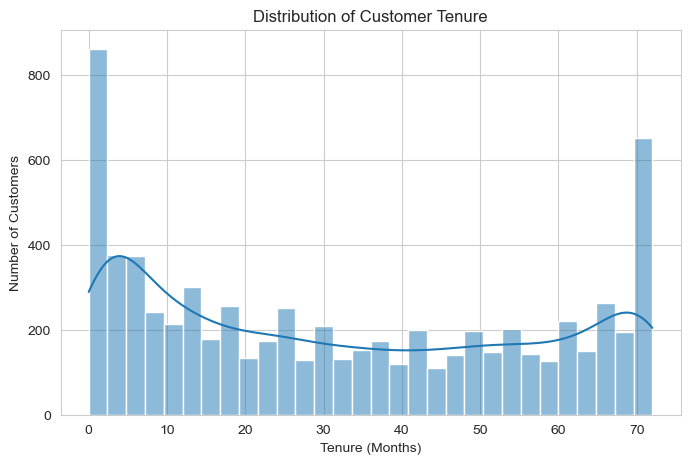

In [34]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="tenure", bins=30, kde=True)
plt.title("Distribution of Customer Tenure")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")
plt.show()

### Visualization 7 — Tenure by Churn Status

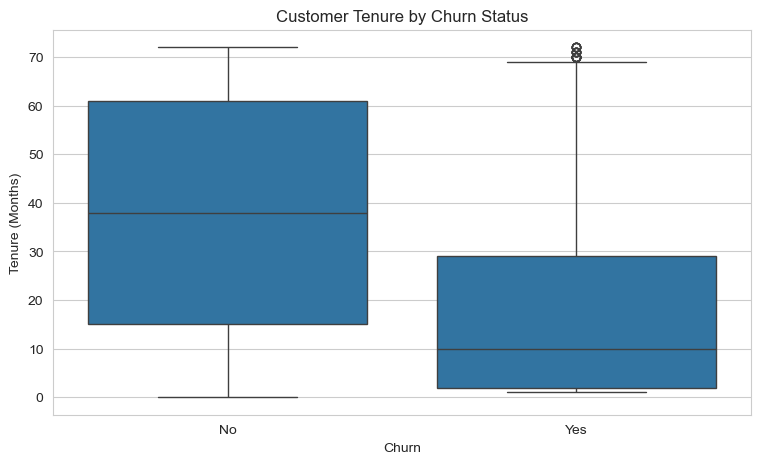

In [35]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="Churn", y="tenure")
plt.title("Customer Tenure by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")
plt.show()

In [36]:
tenure_churn = pd.crosstab(
    df["TenureGroup"], df["Churn"], normalize="index"
) * 100

print("Churn percentage by tenure group:")
tenure_churn.round(2)

Churn percentage by tenure group:


Churn,No,Yes
TenureGroup,,
0-12 months,52.56,47.44
13-24 months,71.29,28.71
25-48 months,79.61,20.39
49-72 months,90.49,9.51


### Visualization 8 — Monthly Charges Distribution by Churn

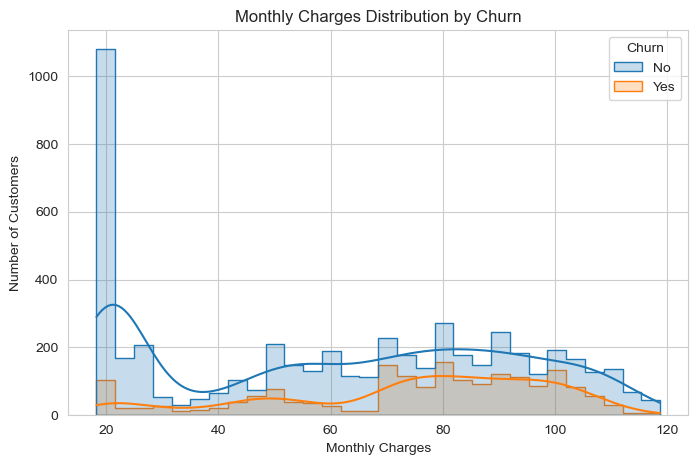

In [37]:
plt.figure(figsize=(8, 5))
sns.histplot(
    data=df,
    x="MonthlyCharges",
    hue="Churn",
    bins=30,
    kde=True,
    element="step"
)
plt.title("Monthly Charges Distribution by Churn")
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")
plt.show()


### Visualization 9 — Tenure vs Monthly Charges

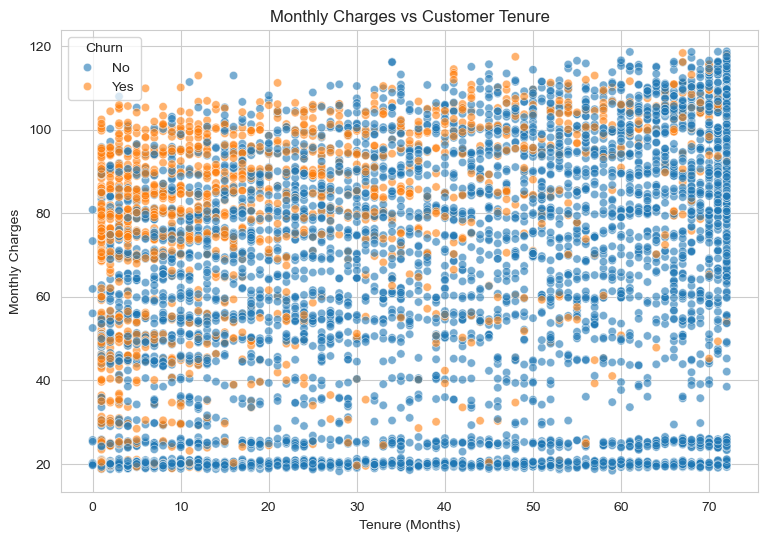

In [38]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df,
    x="tenure",
    y="MonthlyCharges",
    hue="Churn",
    alpha=0.6
)
plt.title("Monthly Charges vs Customer Tenure")
plt.xlabel("Tenure (Months)")
plt.ylabel("Monthly Charges")
plt.show()

### Visualization 10 — Correlation Heatmap

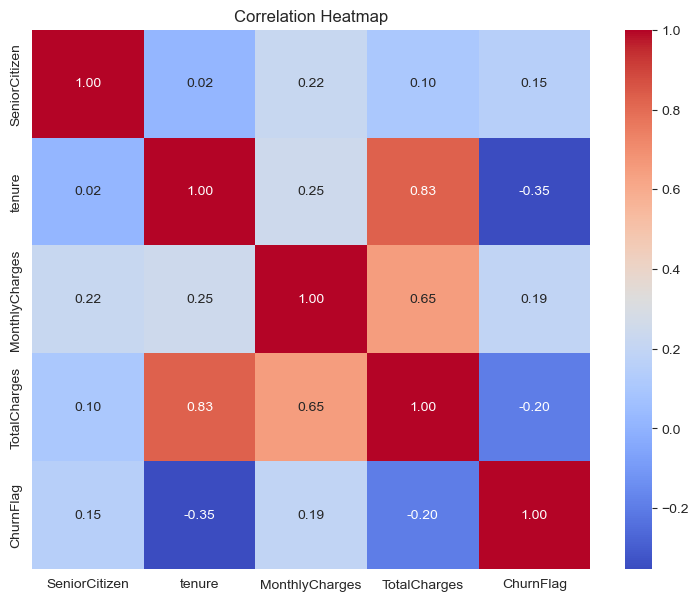

In [39]:
numeric_columns = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "ChurnFlag"
]

correlation = df[numeric_columns].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

### Visualization 11 — Churn by Technical Support

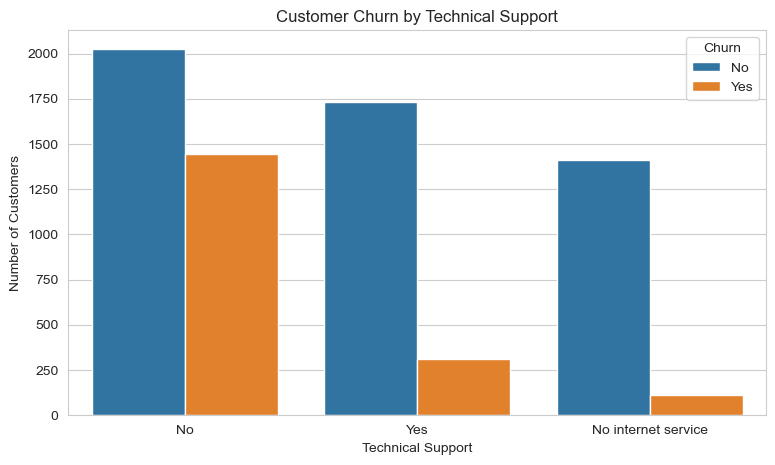

In [40]:
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="TechSupport", hue="Churn")
plt.title("Customer Churn by Technical Support")
plt.xlabel("Technical Support")
plt.ylabel("Number of Customers")
plt.show()

In [41]:
tech_support_churn = pd.crosstab(
    df["TechSupport"], df["Churn"], normalize="index"
) * 100

tech_support_churn.round(2)

Churn,No,Yes
TechSupport,,
No,58.36,41.64
No internet service,92.60,7.40
Yes,84.83,15.17


### Visualization 12 — Churn by Senior Citizen Status

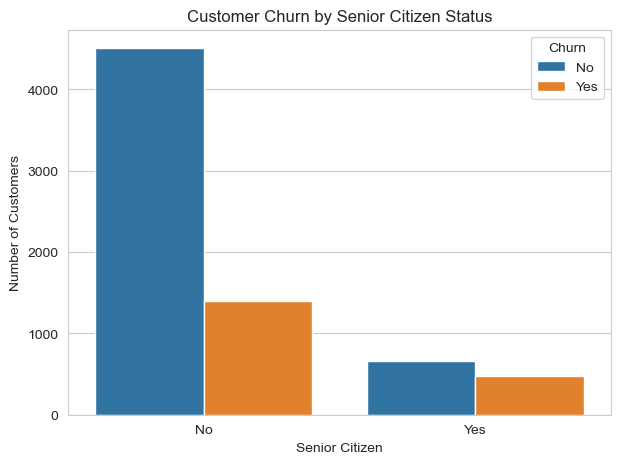

In [42]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="SeniorCitizenLabel", hue="Churn")
plt.title("Customer Churn by Senior Citizen Status")
plt.xlabel("Senior Citizen")
plt.ylabel("Number of Customers")
plt.show()

### Visualization 13 — Churn by Paperless Billing

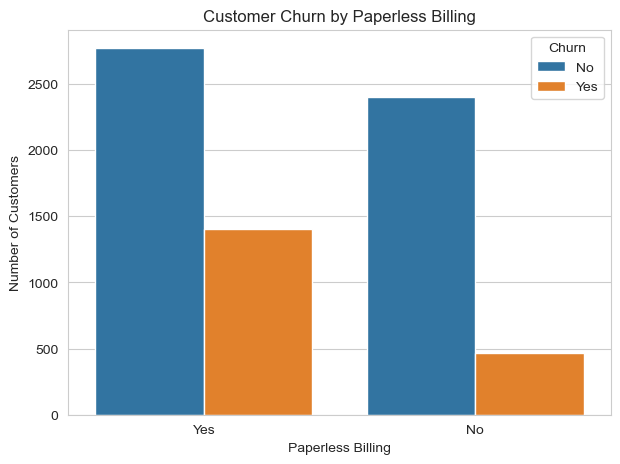

In [43]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="PaperlessBilling", hue="Churn")
plt.title("Customer Churn by Paperless Billing")
plt.xlabel("Paperless Billing")
plt.ylabel("Number of Customers")
plt.show()

## GroupBy Analysis

The following analysis compares average tenure, monthly charges, and total charges between customers who churned and those who remained.

In [44]:
groupby_summary = df.groupby("Churn")[
    ["tenure", "MonthlyCharges", "TotalCharges"]
].mean()

groupby_summary.round(2)

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,37.57,61.27,2549.91
Yes,17.98,74.44,1531.80


## Pivot Table Analysis

This pivot table examines average churn across combinations of contract type and internet service.

In [45]:
contract_internet_pivot = pd.pivot_table(
    df,
    values="ChurnFlag",
    index="Contract",
    columns="InternetService",
    aggfunc="mean"
) * 100

contract_internet_pivot.round(2)

InternetService,DSL,Fiber optic,No
Contract,,,
Month-to-month,32.22,54.61,18.89
One year,9.30,19.29,2.47
Two year,1.91,7.23,0.78


## Multivariate Analysis

The next pivot table examines churn across contract type and payment method simultaneously.


In [46]:
contract_payment_pivot = pd.pivot_table(
    df,
    values="ChurnFlag",
    index="Contract",
    columns="PaymentMethod",
    aggfunc="mean"
) * 100

contract_payment_pivot.round(2)

PaymentMethod,Bank transfer (automatic),Credit card (automatic),Electronic check,Mailed check
Contract,,,,
Month-to-month,34.13,32.78,53.73,31.58
One year,9.72,10.30,18.44,6.82
Two year,3.37,2.24,7.74,0.79


## Correlation Summary

In [47]:
correlation["ChurnFlag"].sort_values(ascending=False).round(3)

ChurnFlag         1.000
MonthlyCharges    0.193
SeniorCitizen     0.151
TotalCharges     -0.198
tenure           -0.352
Name: ChurnFlag, dtype: float64

## Key Insights

### Insight 1 — Contract Type
Month-to-month customers have a substantially higher observed churn rate than customers on one-year and two-year contracts.

### Insight 2 — Customer Tenure
Customers in their first 12 months show considerably higher observed churn than customers with longer tenure.

### Insight 3 — Internet Service
Fiber-optic customers have a higher observed churn rate than DSL customers and customers without internet service in this dataset.

### Insight 4 — Payment Method
Electronic-check customers have a higher observed churn rate than the other payment-method groups in this dataset.

### Insight 5 — Technical Support
Customers without technical support show a substantially higher observed churn rate than customers with technical support.

### Additional Insight — Monthly Charges
Churned customers have a higher average monthly charge than customers who did not churn.

### Additional Insight — Senior Citizen Status
The observed churn rate is higher among senior customers than non-senior customers in this dataset.

> These findings describe associations in the dataset. They should not be interpreted as proof that any individual factor directly causes churn.

##  Recommendations / Business Interpretation

1. Monitor month-to-month customers closely because this segment has a substantially higher observed churn rate.
2. Pay particular attention to customers during the first year of tenure.
3. Investigate the higher churn observed among fiber-optic customers to understand whether service, pricing, competition, or other factors may contribute.
4. Examine the customer journey and payment experience of electronic-check users.
5. Evaluate the availability and usage of technical support as part of customer-retention analysis.
6. Use additional statistical or predictive analysis before making causal claims or implementing major business changes.

This project analyzed the Telco Customer Churn dataset using Python to understand customer churn patterns.

The analysis included data loading, data cleaning, data type correction, missing-value handling, duplicate checking, feature engineering, descriptive statistics, groupby analysis, pivot tables, correlation analysis, and more than 10 visualizations.

The analysis shows that churn varies considerably across contract type, tenure, internet service, payment method, technical support, and customer characteristics. Month-to-month customers and customers with shorter tenure show considerably higher observed churn rates in the dataset.

Overall, the project provides descriptive insights that can support further customer-retention analysis. However, the relationships identified through exploratory analysis should not automatically be interpreted as causal relationships. Further statistical testing or predictive modelling could be used as a future extension.


- [x] Problem definition
- [x] Dataset overview
- [x] Data loading using Pandas
- [x] Missing-value handling
- [x] Duplicate checking
- [x] Data-type correction
- [x] Derived columns
- [x] Filtering/aggregation
- [x] Univariate analysis
- [x] Bivariate analysis
- [x] Multivariate analysis
- [x] GroupBy analysis
- [x] Pivot tables
- [x] Correlation analysis
- [x] 10+ visualizations
- [x] 5+ key insights
- [x] Recommendations
- [x] Final conclusion
      